# Desenvolvimento do modelo de Multi Layer Perceptron (MLP) Classifier Binário de três camadas ocultas
---

***A Fazeres:***
- Buscar `GridSearch`
- Buscar `Ensamble`
- Buscar `LaTeX`
- Buscar `overleaf.com`

Esse notebook mostra o desenvolvimento, de maneira explicada, de um `MLP` de duas camadas. Trará aplicações de `RFE`, limiares relativos à `Sensibilidade`, `Precisão` e `Equilíbrio`.

Os modelos de três e cinco camadas ocultas são consideravelmente mais pesados e difíceis de treinar do que o de duas. Foi apontado que este, por meio do `GridSearchCV`, que a melhor arquitetura é de **funil decrescente**. Portanto, para os modelos com mais camadas, será treinado apenas o modelo com `RFE` e a arquitura mencionada.

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.feature_selection import RFE
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

### 2. Pacotes Predexan
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')

# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


## D) Desenvolvimento do Modelo de MLPde Classificação sem RFE
---

### 1. Instanciação classe MLPClassifier
---

In [8]:

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    max_iter=2000, 
    tol=0.0001,
    learning_rate_init=0.001, 
    learning_rate='adaptive', 
    alpha=0.001, 
    n_iter_no_change=15, 
    solver="adam", 
    activation='relu', 
    random_state=42,
    verbose=True
)

### 2. Treino do modelo
---

In [9]:
pm.imprimir_desempenho(mlp.fit, X_treino, y_treino)

Iteration 1, loss = 0.36947705
Iteration 2, loss = 0.27032645
Iteration 3, loss = 0.21881363
Iteration 4, loss = 0.20344343
Iteration 5, loss = 0.19857987
Iteration 6, loss = 0.19345897
Iteration 7, loss = 0.19000378
Iteration 8, loss = 0.18867680
Iteration 9, loss = 0.18751058
Iteration 10, loss = 0.18690701
Iteration 11, loss = 0.18724551
Iteration 12, loss = 0.18497552
Iteration 13, loss = 0.18391469
Iteration 14, loss = 0.18493257
Iteration 15, loss = 0.18413811
Iteration 16, loss = 0.18299484
Iteration 17, loss = 0.18249471
Iteration 18, loss = 0.18072346
Iteration 19, loss = 0.17999500
Iteration 20, loss = 0.18086868
Iteration 21, loss = 0.18029565
Iteration 22, loss = 0.18005694
Iteration 23, loss = 0.17913201
Iteration 24, loss = 0.17883897
Iteration 25, loss = 0.17861142
Iteration 26, loss = 0.17866327
Iteration 27, loss = 0.17783668
Iteration 28, loss = 0.17749573
Iteration 29, loss = 0.17679957
Iteration 30, loss = 0.17686130
Iteration 31, loss = 0.17555217
Iteration 32, los

MLPClassifier(alpha=0.001, hidden_layer_sizes=(128, 64, 32),
              learning_rate='adaptive', max_iter=2000, n_iter_no_change=15,
              random_state=42, verbose=True)

### 3. Realização das Predições de Teste
---

#### 3.1. Predição Probababilística
---

In [10]:
y_predicao_probabilistica_1 = pm.imprimir_desempenho(mlp.predict_proba, X_teste)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 30/05/2026 14:36:14

    1. TEMPO: 1.0434s (0.02 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 91.13 MB
        - Diferença líquida de RAM no processo: 51.33 MB
        - Total RAM alocada para o processo: 395.84 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 57.6%

  Execução concluída em: 30/05/2026 14:36:15



#### 3.2. Predição Binária
---

In [11]:
y_predicao_binaria_1 = pm.imprimir_desempenho(mlp.predict, X_teste)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 30/05/2026 14:36:15

    1. TEMPO: 0.9542s (0.02 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 91.12 MB
        - Diferença líquida de RAM no processo: 0.00 MB
        - Total RAM alocada para o processo: 395.84 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 51.5%

  Execução concluída em: 30/05/2026 14:36:16



### 4. Desempenho do modelo
---

#### 4.1. Limiar Padrão (0.5)
---

##### 4.1.1. Matriz de Confusão
---

<Axes: >

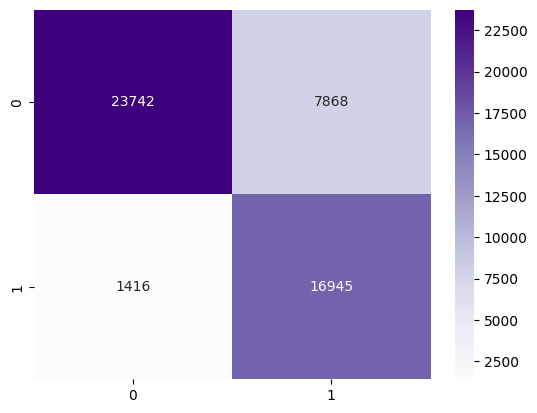

In [12]:
matriz_confusao_1 = confusion_matrix(y_teste, y_predicao_binaria_1)
sns.heatmap(matriz_confusao_1, annot=True, fmt='d', cmap='Purples')

##### 4.1.2. Relatório de Classificação
---

In [13]:
relatorio_classificacao_1 = classification_report(y_teste, y_predicao_binaria_1)
print(relatorio_classificacao_1)

              precision    recall  f1-score   support

         0.0       0.94      0.75      0.84     31610
         1.0       0.68      0.92      0.78     18361

    accuracy                           0.81     49971
   macro avg       0.81      0.84      0.81     49971
weighted avg       0.85      0.81      0.82     49971



##### 4.1.3. Curva ROC-AUC
---

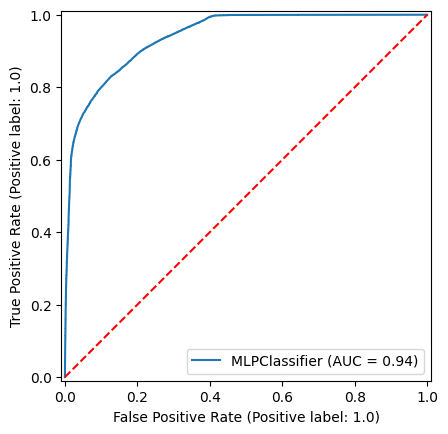

In [14]:
pg.gerar_roc_auc(mlp, X_teste, y_teste)

##### 4.1.4. Curva Precision-Recall
---

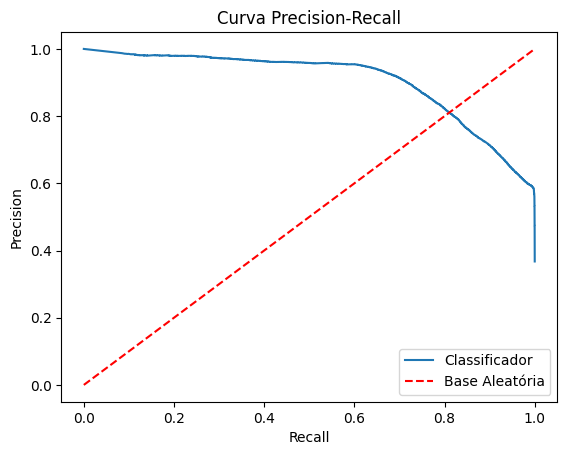

In [15]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_1)

In [16]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_1, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.3250
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 64.31% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.9993
      Recall real obtido: 61.88% (Ataques detectados)
      Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.8882
      Recall neste ponto: 79.02% (Ataques detectados)
      Precision neste ponto: 83.38% (Acerto dos alertas)


##### 4.1.5. Curva de Aprendizado
---

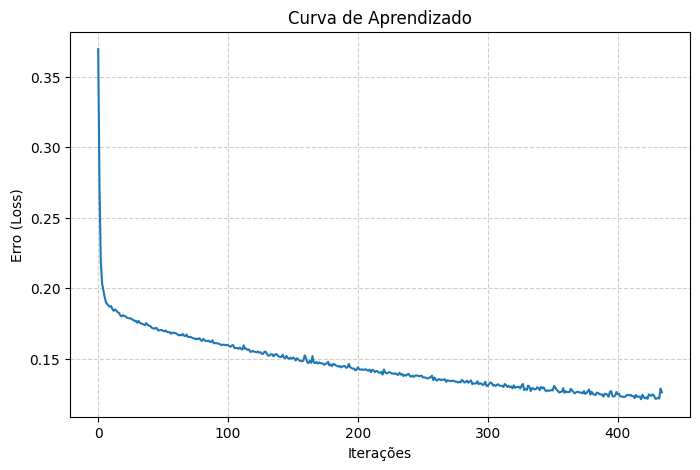

In [17]:
pg.gerar_curva_aprendizado(mlp)

A curva não mostra `Underfitting`, pois não há um número de loss estagnado e sim, alterações que mostram o aprendizado do modelo, via retropropagação. Também não mostra `Overfitting`, pois a queda brusca de loss ocorre somente nas primeiras iterações, apó isso, ela vai se estabilizando. 

#### 4.2. Limiar Equilibrado
---

##### 4.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [18]:
_, limiar_mlp_rfe, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_1)
print(limiar_mlp_rfe)

0.8881910110659068


In [19]:
y_predicao_probabilistica_equilibrada_1 = (y_predicao_probabilistica_1 > limiar_mlp_rfe).astype(int)

<Axes: >

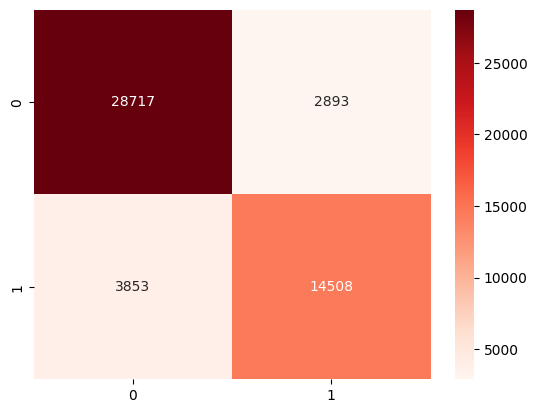

In [20]:
matriz_confusao_equilibrada_1 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_1)
sns.heatmap(matriz_confusao_equilibrada_1, annot=True, fmt='d', cmap='Reds')

##### 4.2.2. Relatório de Classificação
---

In [21]:
relatorio_classificacao_equilibrado_1 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_1)
print(relatorio_classificacao_equilibrado_1)

              precision    recall  f1-score   support

         0.0       0.88      0.91      0.89     31610
         1.0       0.83      0.79      0.81     18361

    accuracy                           0.87     49971
   macro avg       0.86      0.85      0.85     49971
weighted avg       0.86      0.87      0.86     49971



## E) Desenvolvimento do Modelo de MLPde Classificação com RFE + XGBoost Classifier
---

### 1. Aplicação do Recursive Feature Elimination (RFE) para diminuição da dimensionalidade
---

#### 1.1. Instanciamento da classe RFE
---

O objetivo é a diminuição da dimensionalidade, e a escolha das 35 features mais relevantes.

In [22]:
xgb_estimador = XGBClassifier(random_state=42, eval_metric='logloss')

In [23]:
seletor_rfe = RFE(estimator=xgb_estimador, n_features_to_select=35)

#### 1.2. Aplicação do RFE em X_treino
---

In [24]:
X_treino_reduzido = seletor_rfe.fit_transform(X_treino, y_treino)

In [25]:
colunas_originais = X_treino.columns
print(f'Registros e features de treino ANTES da aplicação do RFE:\n - Número de features e registros: {X_treino.shape}\n - Nomes das features: {X_treino.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do RFE:\n - Número de features e registros:  {X_treino_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do RFE:
 - Número de features e registros: (96822, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [26]:
type(X_treino_reduzido)

numpy.ndarray

In [27]:
X_treino_reduzido_df = pd.DataFrame(X_treino_reduzido, columns=colunas_selecionadas)
X_treino_reduzido_df.head()

,duracao_conexao_seg,num_pacotes_origem,num_pacotes_destino,total_bytes_origem,total_bytes_destino,taxa_pacote,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,...,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp,servico_conexao_ftp-data,servico_conexao_http,servico_conexao_outros,servico_conexao_smtp,estado_conexao_CON,estado_conexao_INT,estado_conexao_outros
0,-0.322352,-0.250,-0.250,-0.329992,-0.154433,0.003649,-0.034939,-0.002418,-0.4,-0.333333,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.204962,0.250,1.875,-0.131161,12.130358,0.005210,-0.044014,0.808271,0.0,2.500000,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.176144,-0.125,0.500,-0.285714,3.666471,-0.017687,-0.054756,0.083443,-0.2,0.666667,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.234534,0.125,0.250,-0.175439,0.021139,-0.017863,-0.052917,-0.010829,-0.2,0.166667,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.004935,0.000,-0.125,-0.214703,-0.126248,-0.010849,-0.043752,-0.009800,0.0,-0.166667,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [28]:
for feature in X_treino_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_treino_reduzido_df[feature].min()} a {X_treino_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_treino_reduzido_df[feature].max() - X_treino_reduzido_df[feature].min()}\n')


Feature DURACAO_CONEXAO_SEG:

 - Amplitude: de -0.44357456734279826 a 59.43035021560755

 - Magnitude: 59.87392478295035


Feature NUM_PACOTES_ORIGEM:

 - Amplitude: de -0.5625 a 600.375

 - Magnitude: 600.9375


Feature NUM_PACOTES_DESTINO:

 - Amplitude: de -0.5 a 685.375

 - Magnitude: 685.875


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.42606516290726815 a 5415.2819548872185

 - Magnitude: 5415.708020050126


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4302.6576629477395

 - Magnitude: 4302.862595419848


Feature TAXA_PACOTE:

 - Amplitude: de -0.02273333602547066 a 356.06816390032577

 - Magnitude: 356.0908972363512


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 9427.744951992034

 - Magnitude: 9427.802183623115


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 36.700989512499405

 - Magnitude: 36.717318415859594


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 960.2

 - Magnitude: 960.6


Feature PACO

#### 1.3. Aplicação do RFE em X_teste
---

In [29]:
X_teste_reduzido = seletor_rfe.transform(X_teste)

In [30]:
colunas_originais = X_teste.columns
print(f'Registros e features de treino ANTES da aplicação do PCA:\n - Número de features e registros: {X_teste.shape}\n - Nomes das features: {X_teste.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do PCA:\n - Número de features e registros:  {X_teste_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do PCA:
 - Número de features e registros: (49971, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [31]:
type(X_teste_reduzido)

numpy.ndarray

In [32]:
X_teste_reduzido_df = pd.DataFrame(X_teste_reduzido, columns=colunas_selecionadas)
X_teste_reduzido_df.head()

,duracao_conexao_seg,num_pacotes_origem,num_pacotes_destino,total_bytes_origem,total_bytes_destino,taxa_pacote,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,...,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp,servico_conexao_ftp-data,servico_conexao_http,servico_conexao_outros,servico_conexao_smtp,estado_conexao_CON,estado_conexao_INT,estado_conexao_outros
0,-0.443564,-0.5,-0.5,-0.230576,-0.204932,32.349167,283.916144,-0.016329,-0.4,-0.333333,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.443567,-0.5,-0.5,0.298246,-0.204932,44.488629,1387.032509,-0.016329,-0.4,-0.333333,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.443570,-0.5,-0.5,0.008354,-0.204932,71.195446,1345.152161,-0.016329,-0.4,-0.333333,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.443569,-0.5,-0.5,-0.061821,-0.204932,59.325746,944.612285,-0.016329,-0.4,-0.333333,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.443565,-0.5,-0.5,0.450292,-0.204932,35.586356,1338.854364,-0.016329,-0.4,-0.333333,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [33]:
for feature in X_teste_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_teste_reduzido_df[feature].min()} a {X_teste_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_teste_reduzido_df[feature].max() - X_teste_reduzido_df[feature].min()}\n')


Feature DURACAO_CONEXAO_SEG:

 - Amplitude: de -0.44357456734279826 a 59.43035021560755

 - Magnitude: 59.87392478295035


Feature NUM_PACOTES_ORIGEM:

 - Amplitude: de -0.5625 a 664.75

 - Magnitude: 665.3125


Feature NUM_PACOTES_DESTINO:

 - Amplitude: de -0.5 a 688.125

 - Magnitude: 688.625


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.4277360066833751 a 5996.126148705096

 - Magnitude: 5996.55388471178


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4303.239283617147

 - Magnitude: 4303.444216089255


Feature TAXA_PACOTE:

 - Amplitude: de -0.02273333602547066 a 356.06816390032577

 - Magnitude: 356.0908972363512


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 8294.141531483323

 - Magnitude: 8294.198763114404


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 34.078326484587734

 - Magnitude: 34.094655387947924


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 1063.4

 - Magnitude: 1063.8000000000002


Fea

### 2. Instanciação classe MLPClassifier
---

In [34]:

mlp_rfe = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    max_iter=2000, 
    tol=0.0001,
    learning_rate_init=0.001, 
    learning_rate='adaptive', 
    alpha=0.001, 
    n_iter_no_change=15, 
    solver="adam", 
    activation='relu', 
    random_state=42,
    verbose=True
)

### 3. Treino do modelo
---

In [35]:
pm.imprimir_desempenho(mlp_rfe.fit, X_treino_reduzido_df, y_treino)

Iteration 1, loss = 0.40039960
Iteration 2, loss = 0.26188933
Iteration 3, loss = 0.22471715
Iteration 4, loss = 0.21203814
Iteration 5, loss = 0.21139243
Iteration 6, loss = 0.19715413
Iteration 7, loss = 0.19337093
Iteration 8, loss = 0.19041203
Iteration 9, loss = 0.19097425
Iteration 10, loss = 0.19066610
Iteration 11, loss = 0.18798475
Iteration 12, loss = 0.18613200
Iteration 13, loss = 0.18628795
Iteration 14, loss = 0.18394362
Iteration 15, loss = 0.18328137
Iteration 16, loss = 0.18151998
Iteration 17, loss = 0.18814823
Iteration 18, loss = 0.18349730
Iteration 19, loss = 0.18130629
Iteration 20, loss = 0.18117105
Iteration 21, loss = 0.17984835
Iteration 22, loss = 0.17935043
Iteration 23, loss = 0.17869311
Iteration 24, loss = 0.17887821
Iteration 25, loss = 0.17781730
Iteration 26, loss = 0.17792099
Iteration 27, loss = 0.17724884
Iteration 28, loss = 0.17584847
Iteration 29, loss = 0.17627207
Iteration 30, loss = 0.17536941
Iteration 31, loss = 0.17439614
Iteration 32, los

MLPClassifier(alpha=0.001, hidden_layer_sizes=(128, 64, 32),
              learning_rate='adaptive', max_iter=2000, n_iter_no_change=15,
              random_state=42, verbose=True)

### 4. Realização das Predições de Teste
---

#### 4.1. Predição Probababilística
---

In [36]:
y_predicao_probabilistica_2 = pm.imprimir_desempenho(mlp_rfe.predict_proba, X_teste_reduzido_df)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 30/05/2026 14:50:08

    1. TEMPO: 0.7203s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 73.20 MB
        - Diferença líquida de RAM no processo: 0.78 MB
        - Total RAM alocada para o processo: 497.25 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 76.3%

  Execução concluída em: 30/05/2026 14:50:09



#### 4.2. Predição Binária
---

In [37]:
y_predicao_binaria_2 = pm.imprimir_desempenho(mlp_rfe.predict, X_teste_reduzido_df)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 30/05/2026 14:50:09

    1. TEMPO: 0.7284s (0.01 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 73.20 MB
        - Diferença líquida de RAM no processo: 0.38 MB
        - Total RAM alocada para o processo: 497.63 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 70.5%

  Execução concluída em: 30/05/2026 14:50:10



### 5. Desempenho do modelo
---

#### 5.1. Limiar Padrão (0.5)
---

##### 5.1.1. Matriz de Confusão
---

<Axes: >

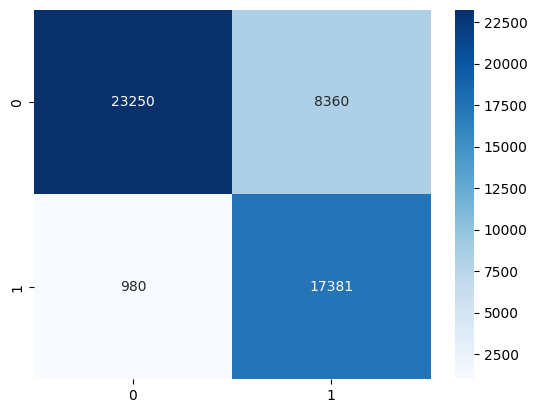

In [38]:
matriz_confusao_2 = confusion_matrix(y_teste, y_predicao_binaria_2)
sns.heatmap(matriz_confusao_2, annot=True, fmt='d', cmap='Blues')

##### 5.1.2. Relatório de Classificação
---

In [39]:
relatorio_classificacao_2 = classification_report(y_teste, y_predicao_binaria_2)
print(relatorio_classificacao_2)

              precision    recall  f1-score   support

         0.0       0.96      0.74      0.83     31610
         1.0       0.68      0.95      0.79     18361

    accuracy                           0.81     49971
   macro avg       0.82      0.84      0.81     49971
weighted avg       0.86      0.81      0.82     49971



##### 5.1.3. Curva ROC-AUC
---

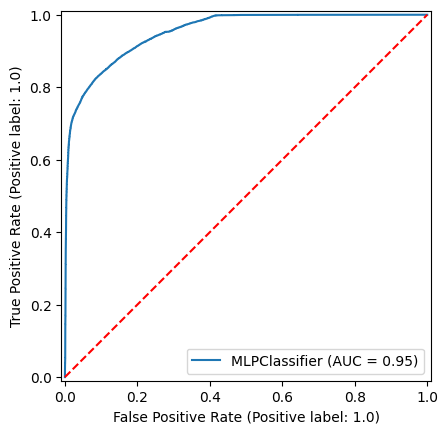

In [40]:
pg.gerar_roc_auc(mlp_rfe, X_teste_reduzido_df, y_teste)

##### 5.1.4. Curva Precision-Recall
---

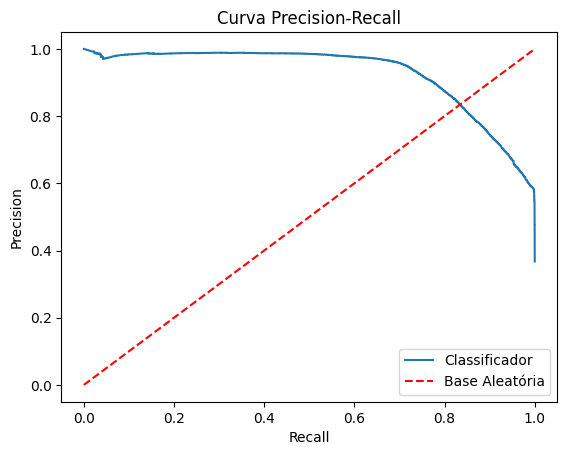

In [41]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_2)

In [42]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_2, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4889
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 66.99% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.9200
      Recall real obtido: 71.56% (Ataques detectados)
      Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.7501
      Recall neste ponto: 82.11% (Ataques detectados)
      Precision neste ponto: 85.28% (Acerto dos alertas)


##### 5.1.5. Curva de Aprendizado
---

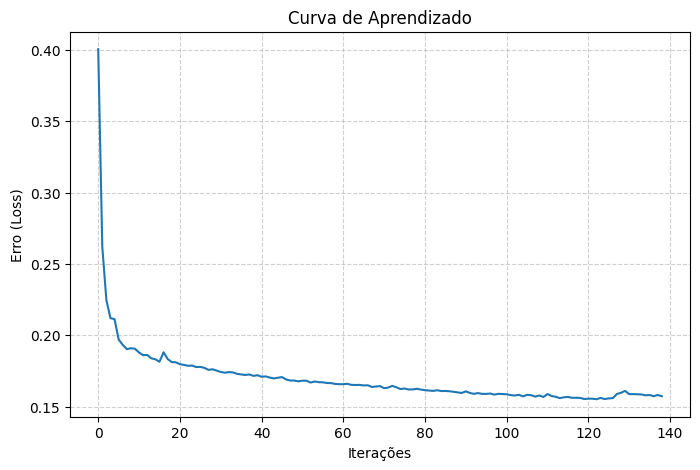

In [43]:
pg.gerar_curva_aprendizado(mlp_rfe)

#### 5.2. Limiar Equilibrado
---

##### 5.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [44]:
_, limiar_mlp_rfe, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_2)
print(limiar_mlp_rfe)

0.7500688115661951


In [45]:
y_predicao_probabilistica_equilibrada_2 = (y_predicao_probabilistica_2 > limiar_mlp_rfe).astype(int)

<Axes: >

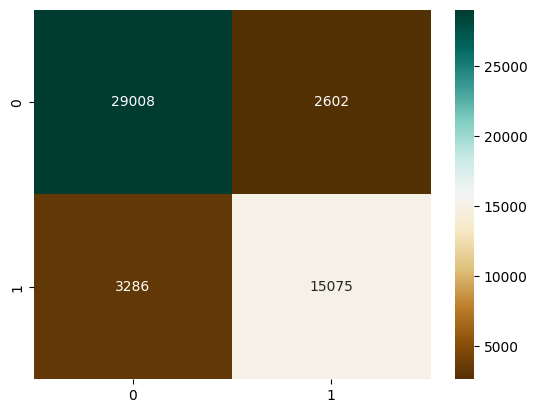

In [46]:
matriz_confusao_equilibrada_2 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_2)
sns.heatmap(matriz_confusao_equilibrada_2, annot=True, fmt='d', cmap='BrBG')

##### 5.2.2. Relatório de Classificação
---

In [47]:
relatorio_classificacao_equilibrado_2 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_2)
print(relatorio_classificacao_equilibrado_2)

              precision    recall  f1-score   support

         0.0       0.90      0.92      0.91     31610
         1.0       0.85      0.82      0.84     18361

    accuracy                           0.88     49971
   macro avg       0.88      0.87      0.87     49971
weighted avg       0.88      0.88      0.88     49971



## F) Comparando os Limiares
---

#### 1. Dados de Desempenho Modelo
---

In [48]:
print('\nComparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:\n')

print('\n1. MODELO CAMPEÃO SEM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_1)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_1)

print('\n\n2. MODELO CAMPEÃO COM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_2)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_2)



Comparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:


1. MODELO CAMPEÃO SEM RFE:

 - Padrão:

O total de predições de teste foi 49971.


 -> Classe 0:
    - Verdadeiro Negativo (TN): há 23742 casos, o que representa, aproximadamente, 47.51% do total de predições de teste.
    - Falso Negativo (FN): há 1416 casos, o que representa, aproximadamente, 2.83% do total de predições de teste.

 -> Classe 1:
   - Verdadeiro Positivo (TP): há 16945 casos, o que representa, aproximadamente, 33.91% do total de predições de teste.
   - Falso Positivo (FP): há 7868 casos, o que representa, aproximadamente, 15.75% do total de predições de teste.


 -> Resultados Gerais:
    - A Acurácia total do modelo se dá por: (tp + tn) / total. Seu valor é 0.8142.
    - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a 40687, de um total de 49971. Corresponde a, aproximadamente, 81.42% das predições.
    - A quantidade de vezes que o modelo

#### 2. Diferenças entre os desempenhos
---

In [49]:
# Modelo sem RFE
dados_modelo_1 = pm.extracao_desempenho_modelo(matriz_confusao_1)
dados_modelo_equilibrado_1 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_1)

# Modelo com RFE
dados_modelo_2 = pm.extracao_desempenho_modelo(matriz_confusao_2)
dados_modelo_equilibrado_2 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_2)

# Total de registros
total_registros = dados_modelo_1['tn'] + dados_modelo_1['tp'] + dados_modelo_1['fn'] + dados_modelo_1['fp']

In [53]:
print('A) As diferenças métricas entre os modelos são:\n')
print('Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).')

print('\n1. Limiar Padrão:')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_1["tn"]} | Com RFE - {dados_modelo_2["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_2["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_1["tp"]} | Com RFE - {dados_modelo_2["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_2["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_1["fn"]} | Com RFE - {dados_modelo_2["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_2["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_1["fp"]} | Com RFE - {dados_modelo_2["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_2["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_1["accuracy"]} | Com RFE - {dados_modelo_2["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Sem RFE - {dados_modelo_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall(1): Sem RFE - {dados_modelo_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision(0): Sem RFE - {dados_modelo_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision(1): Sem RFE - {dados_modelo_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score(0): Sem RFE - {dados_modelo_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score(1): Sem RFE - {dados_modelo_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n2. Limiar Equilibrado:')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_equilibrado_1["tn"]} | Com RFE - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_equilibrado_1["tp"]} | Com RFE - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_equilibrado_1["fn"]} | Com RFE - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_equilibrado_1["fp"]} | Com RFE - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_equilibrado_1["accuracy"]} | Com RFE - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score (0): Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n')
print('-'*220)
print('\n')

print('\nB) As diferenças métricas entre os limiares dos modelos são:\n')
print('\n1. Modelo sem RFE:')
print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo_1["tn"]} | Equilibrado - {dados_modelo_equilibrado_1["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_1["tp"]} | Equilibrado - {dados_modelo_equilibrado_1["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_1["fn"]} | Equilibrado - {dados_modelo_equilibrado_1["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_1["fp"]} | Equilibrado - {dados_modelo_equilibrado_1["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_1["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_1["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Padrão - {dados_modelo_1["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Padrão - {dados_modelo_1["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 1):.2f}%')
print(f'\n    Precision (0): Padrão - {dados_modelo_1["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Padrão - {dados_modelo_1["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 1):.2f}%')
print(f'\n    F1-Score (0): Padrão - {dados_modelo_1["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Padrão - {dados_modelo_1["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 1):.2f}%')

print('\n2. Modelo com RFE:')
print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo_2["tn"]} | Equilibrado - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_2["tp"]} | Equilibrado - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_2["fn"]} | Equilibrado - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_2["fp"]} | Equilibrado - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_2["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Métricas por Classe:')
print(f'    Recall (0): Padrão - {dados_modelo_2["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Recall (1): Padrão - {dados_modelo_2["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision (0): Padrão - {dados_modelo_2["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    Precision (1): Padrão - {dados_modelo_2["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score (0): Padrão - {dados_modelo_2["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')
print(f'    F1-Score (1): Padrão - {dados_modelo_2["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

A) As diferenças métricas entre os modelos são:

Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).

1. Limiar Padrão:

 - Métricas Básicas:
    TN: Sem RFE - 23742 | Com RFE - 23250 -> Diferença de 492 ou 0.98%
    TP: Sem RFE - 16945 | Com RFE - 17381 -> Diferença de -436 ou -0.87%
    FN: Sem RFEo - 1416 | Com RFE - 980 -> Diferença de 436 ou 0.87%
    FP: Sem RFE - 7868 | Com RFE - 8360 -> Diferença de -492 ou -0.98%

 - Acurácia Geral do Modelo:
    Acurácia: Sem RFE - 0.8142 | Com RFE - 0.8131 -> Diferença de 0.0011 ou 0.11%

 - Métricas por Classe:
    Recall (0): Sem RFE - 0.7511 | Com RFE - 0.7355 -> Diferença de 0.0156 ou 1.56%
    Recall(1): Sem RFE - 0.9229 | Com RFE - 0.9466 -> Diferença de -0.0237 ou -2.37%

    Precision(0): Sem RFE - 0.9437 | Com RFE - 0.9596 -> Diferença de -0.0159 ou -1.59%
    Precision(1): Sem 

## G) Persisitindo os Modelos
---

### 1. Modelo sem RFE
---

In [51]:
joblib.dump(mlp, '../persistencia/modelos_persistentes/mlp/mlp_3c/mlp_3c.pkl')

['../persistencia/modelos_persistentes/mlp/mlp_3c/mlp_3c.pkl']

### 2. Modelo com RFE
---

In [52]:
joblib.dump(mlp_rfe, '../persistencia/modelos_persistentes/mlp/mlp_3c/mlp_3c_rfe.pkl')

['../persistencia/modelos_persistentes/mlp/mlp_3c/mlp_3c_rfe.pkl']